# EDA and results

Visual companion to [reports/report.md](../reports/report.md). Reads the artefacts written by
`src.run_ocr`, `src.train` and `src.evaluate`; runs in seconds.

In [1]:
import json, os, sys
from collections import Counter
from pathlib import Path
if Path.cwd().name == "notebooks": os.chdir("..")
sys.path.insert(0, ".")

import matplotlib.pyplot as plt, numpy as np, pandas as pd
from IPython.display import Image as Img, display
from PIL import Image
from src.text_normalize import normalize

BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "axes.axisbelow": True})
df = pd.read_csv("outputs/ocr_dataset.csv", keep_default_na=False)
m = json.load(open("outputs/metrics.json"))

## 1. Data
1,100 images, balanced, mostly 640 px on the long side. Natural photos with synthetic overlay text.

In [2]:
sizes = pd.DataFrame([(p.parent.name, max(Image.open(p).size)) for p in Path("images").rglob("*.jpg")], columns=["class", "long_side"])
display(sizes["class"].value_counts().to_frame("images"), sizes["long_side"].value_counts().head(3).to_frame("images"))

,images
class,
alcohol,550
non_alcohol,550


,images
long_side,
640,903
500,152
612,22


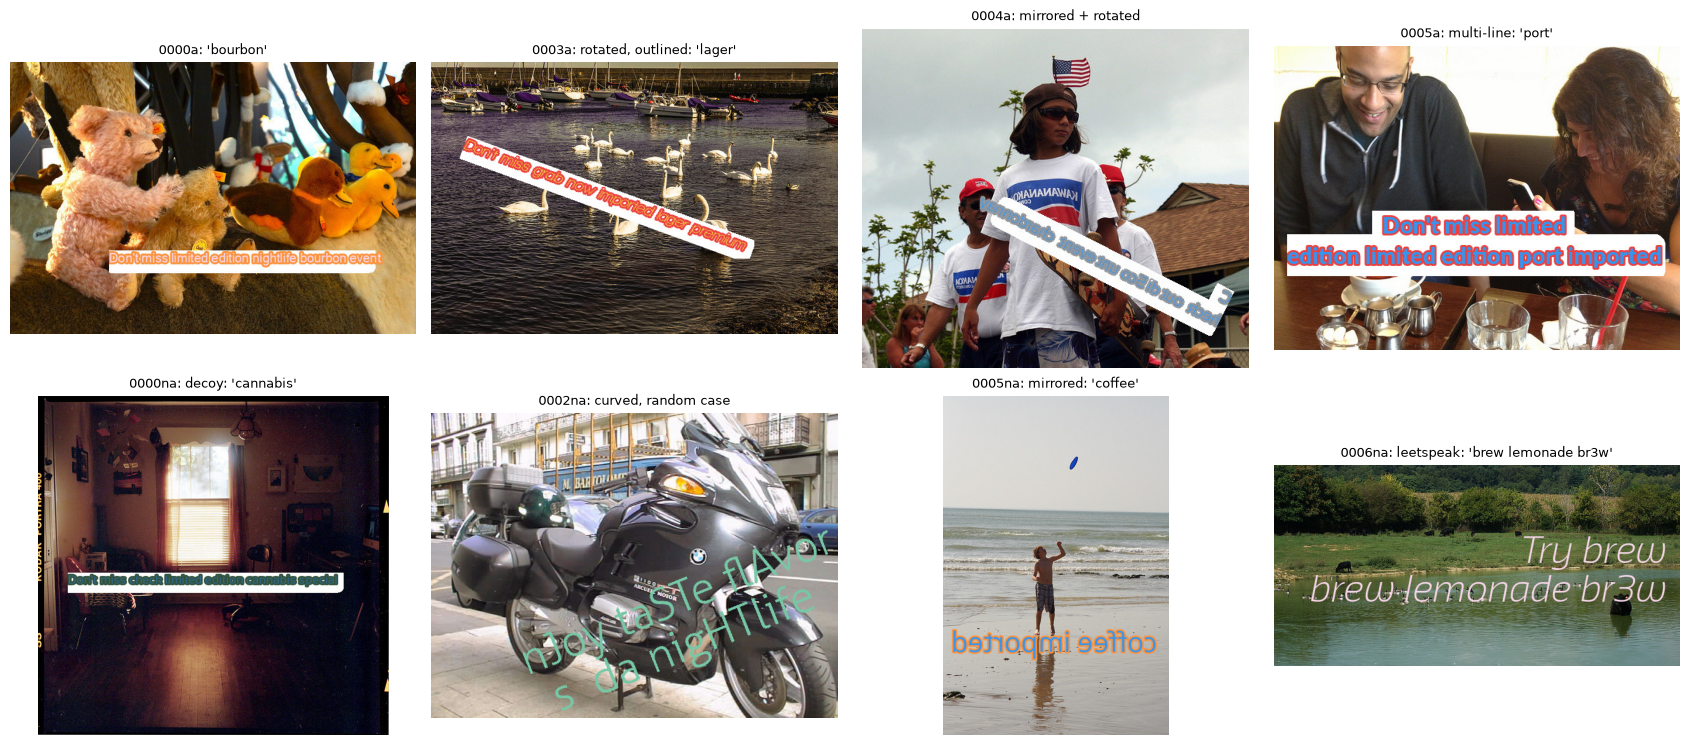

In [3]:
examples = [("alcohol/0000a", "'bourbon'"), ("alcohol/0003a", "rotated, outlined: 'lager'"), ("alcohol/0004a", "mirrored + rotated"),
            ("alcohol/0005a", "multi-line: 'port'"), ("non_alcohol/0000na", "decoy: 'cannabis'"), ("non_alcohol/0002na", "curved, random case"),
            ("non_alcohol/0005na", "mirrored: 'coffee'"), ("non_alcohol/0006na", "leetspeak: 'brew lemonade br3w'")]
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, (f, title) in zip(axes.ravel(), examples):
    ax.imshow(Image.open(f"images/{f}.jpg")); ax.set_title(f"{f.split('/')[1]}: {title}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. The label is one word; the rest is template
Share of images containing each word (Paddle OCR text). Beverage words separate the classes perfectly.
Template words appear in both classes, some with a skew the model must not learn. "brew", "bar" and "party" are
designed confounders that are equally common in both classes.

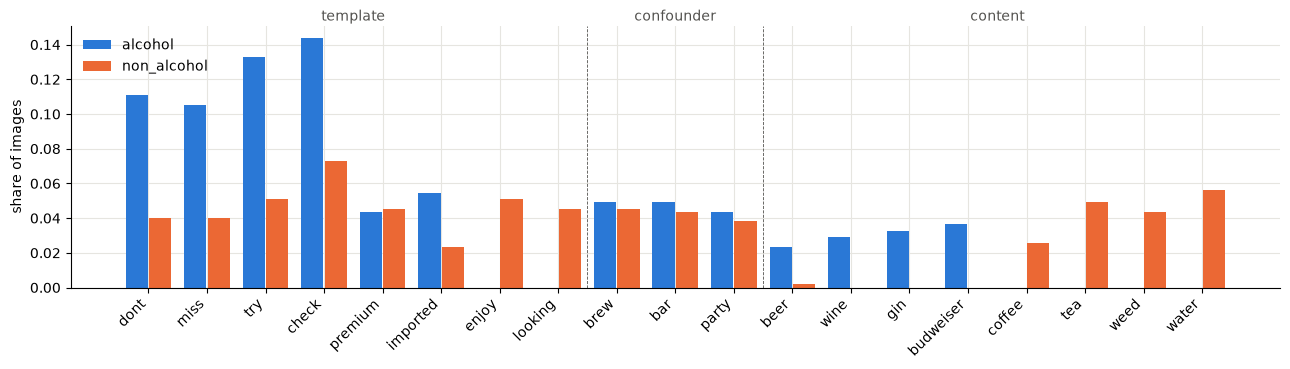

In [4]:
cnt = {y: Counter(w for t in df[df.label == y].text_pm_orig for w in set(normalize(t).split())) for y in (0, 1)}
n = df.label.value_counts()
groups = {"template": ["dont", "miss", "try", "check", "premium", "imported", "enjoy", "looking"],
          "confounder": ["brew", "bar", "party"],
          "content": ["beer", "wine", "gin", "budweiser", "coffee", "tea", "weed", "water"]}
words = [w for ws in groups.values() for w in ws]
x = np.arange(len(words))
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.bar(x - 0.2, [cnt[1][w] / n[1] for w in words], 0.38, color=BLUE, label="alcohol")
ax.bar(x + 0.2, [cnt[0][w] / n[0] for w in words], 0.38, color=ORANGE, label="non_alcohol")
ax.set_xticks(x, words, rotation=45, ha="right"); ax.set_ylabel("share of images")
start = 0
for g, ws in groups.items():
    ax.text(start + len(ws) / 2 - 0.5, 1.02, g, ha="center", color=MUTED, transform=ax.get_xaxis_transform())
    start += len(ws)
    if start < len(words): ax.axvline(start - 0.5, color=MUTED, lw=0.6, ls="--")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()

## 3. OCR: the main lever
Share of alcohol images where the beverage word is read, per OCR configuration.

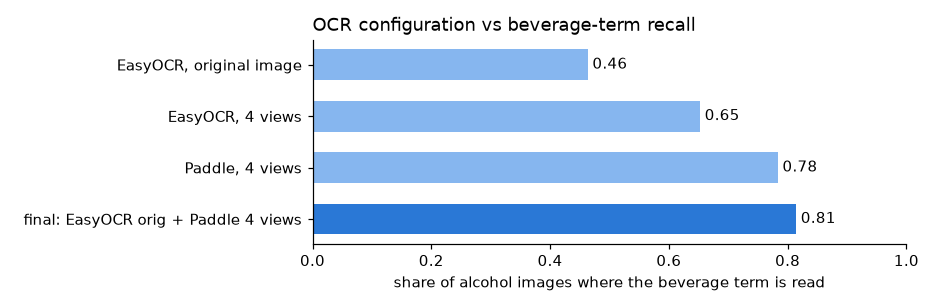

In [5]:
display(Img("reports/figures/ocr_views.png"))

## 4. Results

In [6]:
pd.DataFrame({**{"CV: " + k: v for k, v in m["cv_models"].items()},
              "hold-out (final)": m["holdout"]}).T[["precision", "recall", "f1", "roc_auc"]]

,precision,recall,f1,roc_auc
CV: lexicon rule (alcohol term found),0.9972,0.8114,0.8947,NaN
CV: TF-IDF logistic regression,0.9163,0.9705,0.9426,0.9919
"CV: fusion (final), threshold 0.5",0.9183,0.9705,0.9436,0.9933
"CV: fusion (final), threshold 0.57",0.9853,0.9136,0.9481,0.9933
hold-out (final),0.9808,0.9273,0.9533,0.9955


In [7]:
pd.DataFrame(m["unseen_brands"]).T[["precision", "recall", "f1", "roc_auc"]].rename_axis("unseen beverage names")

,precision,recall,f1,roc_auc
unseen beverage names,,,,
TF-IDF logistic regression,0.6911,0.7200,0.7053,0.7773
fusion (final),0.9205,0.9473,0.9337,0.9905


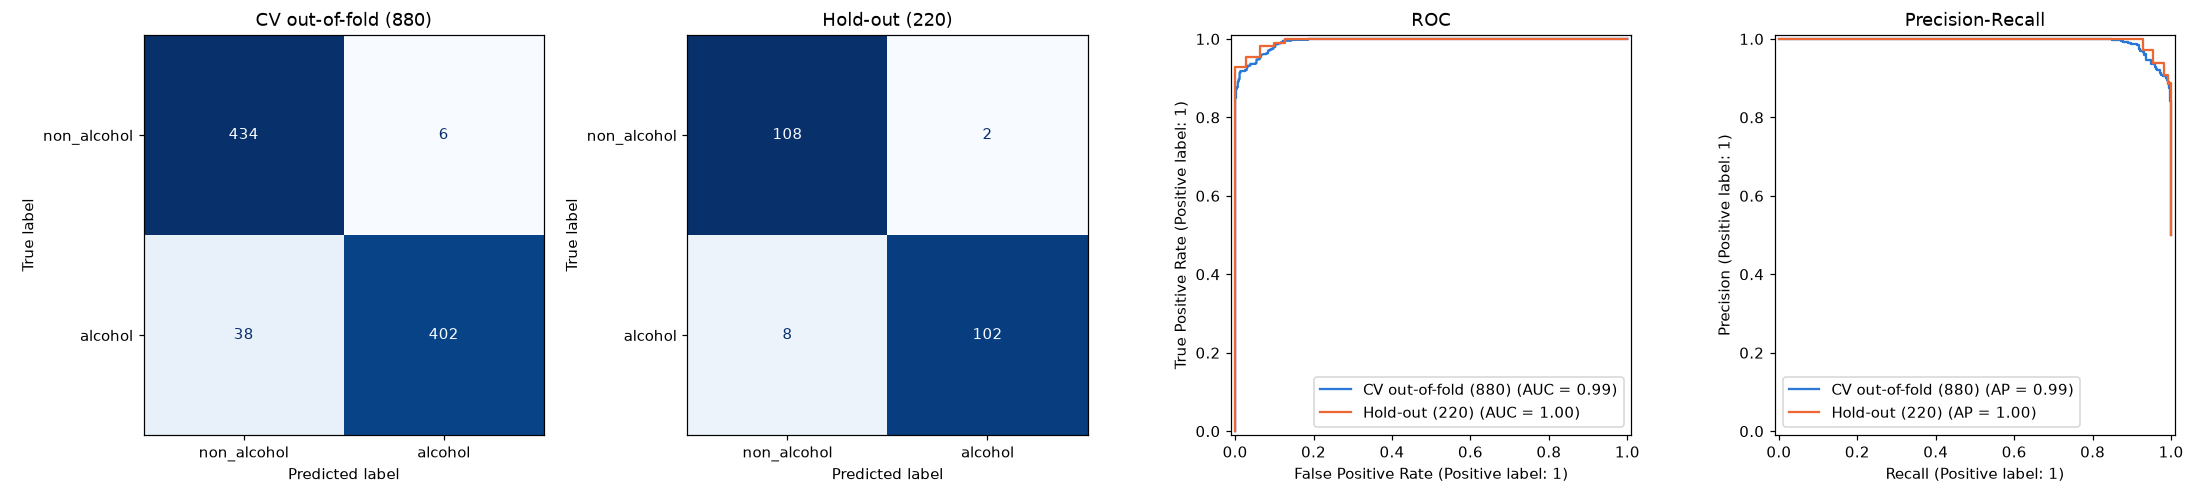

In [8]:
display(Img("reports/figures/confusion_roc_pr.png"))

## 5. Failure cases
The 8 most confident errors. All are low-confidence (p between 0.33 and 0.63).

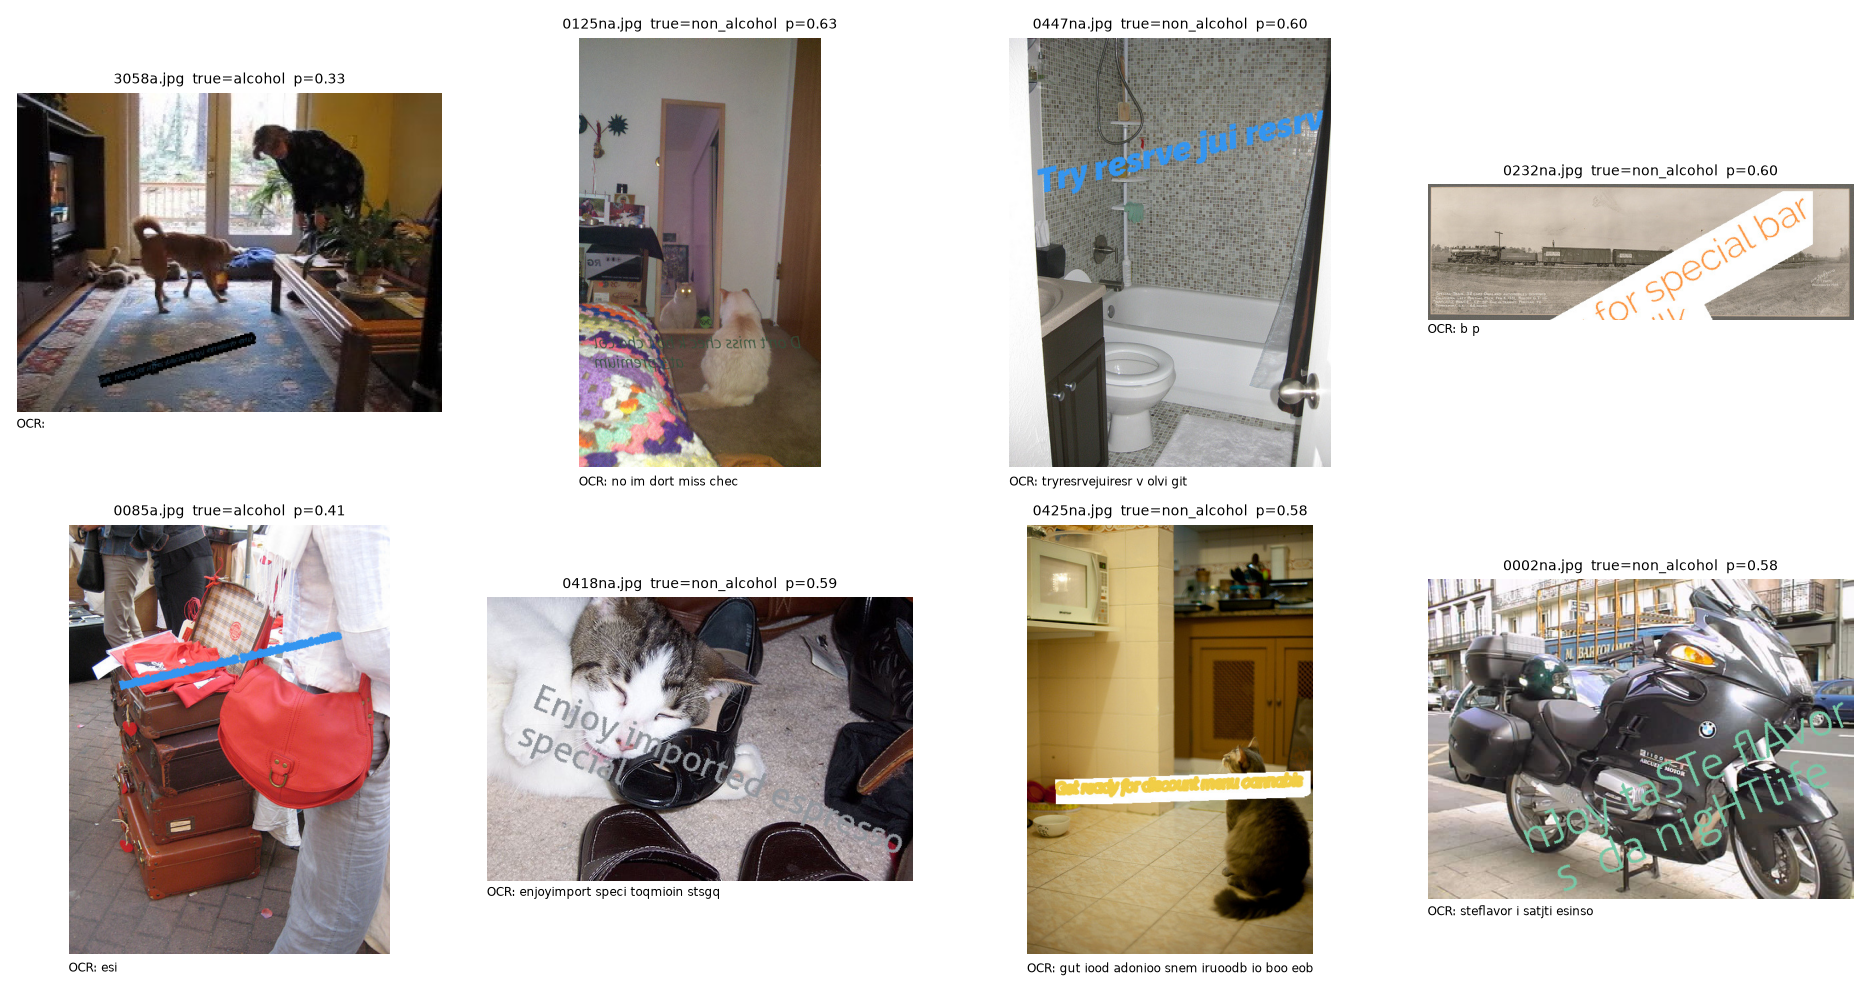

In [9]:
display(Img("reports/figures/failure_cases.png"))